### Assignment 1:  Download heart dataset from the following link:
 - https://www.kaggle.com/zhaoyingzhu/heartcsv. Perform the
 - following operations on the given dataset: (a) Find shape of data
 - and missing values; (b) Find data type of each column; (c)
 - Finding out zero's; (d) Find mean age of patients; (e) Now extract
 - only Age, Sex, ChestPain, RestBP, Chol. Randomly divide the
 - dataset in training (75%) and testing (25%).

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("Heart.csv")

In [4]:
df


,Unnamed: 0,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,1,63,1,typical,145,233,1,2,150,0,2.3,3,0.0,fixed,No
1,2,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3.0,normal,Yes
2,3,67,1,asymptomatic,120,229,0,2,129,1,2.6,2,2.0,reversable,Yes
3,4,37,1,nonanginal,130,250,0,0,187,0,3.5,3,0.0,normal,No
4,5,41,0,nontypical,130,204,0,2,172,0,1.4,1,0.0,normal,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,299,45,1,typical,110,264,0,0,132,0,1.2,2,0.0,reversable,Yes
299,300,68,1,asymptomatic,144,193,1,0,141,0,3.4,2,2.0,reversable,Yes
300,301,57,1,asymptomatic,130,131,0,0,115,1,1.2,2,1.0,reversable,Yes
301,302,57,0,nontypical,130,236,0,2,174,0,0.0,2,1.0,normal,Yes


In [5]:
print("Dataset shape:", df.shape)


Dataset shape: (303, 15)


In [6]:
print("\nData types:\n", df.dtypes)



Data types:
 Unnamed: 0      int64
Age             int64
Sex             int64
ChestPain      object
RestBP          int64
Chol            int64
Fbs             int64
RestECG         int64
MaxHR           int64
ExAng           int64
Oldpeak       float64
Slope           int64
Ca            float64
Thal           object
AHD            object
dtype: object


In [7]:
print("\nMissing values:\n", df.isnull().sum())



Missing values:
 Unnamed: 0    0
Age           0
Sex           0
ChestPain     0
RestBP        0
Chol          0
Fbs           0
RestECG       0
MaxHR         0
ExAng         0
Oldpeak       0
Slope         0
Ca            4
Thal          2
AHD           0
dtype: int64


In [8]:
print("\nZero count in each column:\n", (df == 0).sum())



Zero count in each column:
 Unnamed: 0      0
Age             0
Sex            97
ChestPain       0
RestBP          0
Chol            0
Fbs           258
RestECG       151
MaxHR           0
ExAng         204
Oldpeak        99
Slope           0
Ca            176
Thal            0
AHD             0
dtype: int64


In [9]:
print("\nMean age:", df["Age"].mean())



Mean age: 54.43894389438944


In [10]:
columns = ["Age", "Sex", "ChestPain", "RestBP", "Chol"]


In [12]:
data = df[columns]


In [13]:
train_data, test_data = train_test_split(data, test_size=0.25, random_state=42)


In [14]:
print("\nSelected data:\n", data.head())



Selected data:
    Age  Sex     ChestPain  RestBP  Chol
0   63    1       typical     145   233
1   67    1  asymptomatic     160   286
2   67    1  asymptomatic     120   229
3   37    1    nonanginal     130   250
4   41    0    nontypical     130   204


In [15]:
print("Training shape:", train_data.shape)


Training shape: (227, 5)


In [16]:
print("Testing shape:", test_data.shape)


Testing shape: (76, 5)


## Assignment 2:  Given a set of sample points in N dimensional feature space.
 - Write a program to fit the points with a hyper plane using Linear
 - Regression. Calculate sum of residual error.

In [17]:
import numpy as np
from sklearn.linear_model import LinearRegression

In [18]:
np.random.seed(52)
X = np.random.rand(10, 3) * 10
y = 5 + 2*X[:, 0] + 3*X[:, 1] - X[:, 2] + np.random.randn(10)

In [19]:
model = LinearRegression().fit(X, y)
predictions = model.predict(X)
residuals = y - predictions

In [20]:
print("Coefficients:", model.coef_)


Coefficients: [ 2.0063521   2.87411937 -0.85027946]


In [21]:
print("Intercept:", model.intercept_)


Intercept: 4.799954496188537


In [22]:
print("Predictions:", predictions)


Predictions: [20.2729686  14.75963637 25.1551369  27.04834184 25.61543969 34.10991307
 33.64328895 12.51320467 36.88991401 40.26512294]


In [23]:
print("Residuals:", residuals)


Residuals: [ 1.31061126 -0.59216281  1.56667491 -0.54275821 -0.49806156 -0.50860118
 -0.86723662 -0.42039024  0.07076965  0.48115481]


In [24]:
print("Sum of residual error:", np.sum(residuals))


Sum of residual error: -8.881784197001252e-15


In [25]:
print("Sum of squared residual errors:", np.sum(residuals**2))


Sum of squared residual errors: 6.48950149370536


# Asssignment 3 :  Write a program that provides option to compute different
 - distance measures between two points in the N dimensional
 - feature space. Consider some sam

In [1]:
import numpy as np
from scipy.spatial import distance

In [2]:
def compute_distance(a, b, method, p=2):
    if method == "euclidean": return distance.euclidean(a, b)
    if method == "manhattan": return distance.cityblock(a, b)
    if method == "minkowski": return distance.minkowski(a, b, p)
    if method == "chebyshev": return distance.chebyshev(a, b)
    if method == "cosine": return distance.cosine(a, b)
    raise ValueError("Unknown distance method")

In [3]:
dataset = np.array([[3,2,1], [5,6,4], [1,0,1], [4,4,4]])
print("Sample dataset:\n", dataset)

Sample dataset:
 [[3 2 1]
 [5 6 4]
 [1 0 1]
 [4 4 4]]


In [4]:
a, b = dataset[0], dataset[1]
print("Points:", a, "and", b)
for method in ["euclidean", "manhattan", "cosine", "chebyshev"]:
    print(method.title(), "distance:", compute_distance(a, b, method))
print("Minkowski (p=3):", compute_distance(a, b, "minkowski", p=3))


Points: [3 2 1] and [5 6 4]
Euclidean distance: 5.385164807134504
Manhattan distance: 9
Cosine distance: 0.05582539899658234
Chebyshev distance: 4
Minkowski (p=3): 4.626065009182741


# Assignment :4  Develop a program to Compute the correlation matrix to
- understand the relationships between pairs of features. 
- Visualize the correlation matrix using a heatmap to know which variables have strong positive/negative correlations. 
- Create a pair plot to visualize pairwise relationships between features. 
- Use California Housing dataset

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing

In [9]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame
print("First five rows:\n", df.head())

First five rows:
    MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  


In [10]:
corr = df.corr()
print("\nCorrelation matrix:\n", corr.round(2))


Correlation matrix:
              MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  \
MedInc         1.00     -0.12      0.33      -0.06        0.00      0.02   
HouseAge      -0.12      1.00     -0.15      -0.08       -0.30      0.01   
AveRooms       0.33     -0.15      1.00       0.85       -0.07     -0.00   
AveBedrms     -0.06     -0.08      0.85       1.00       -0.07     -0.01   
Population     0.00     -0.30     -0.07      -0.07        1.00      0.07   
AveOccup       0.02      0.01     -0.00      -0.01        0.07      1.00   
Latitude      -0.08      0.01      0.11       0.07       -0.11      0.00   
Longitude     -0.02     -0.11     -0.03       0.01        0.10      0.00   
MedHouseVal    0.69      0.11      0.15      -0.05       -0.02     -0.02   

             Latitude  Longitude  MedHouseVal  
MedInc          -0.08      -0.02         0.69  
HouseAge         0.01      -0.11         0.11  
AveRooms         0.11      -0.03         0.15  
AveBedrms        0.07    

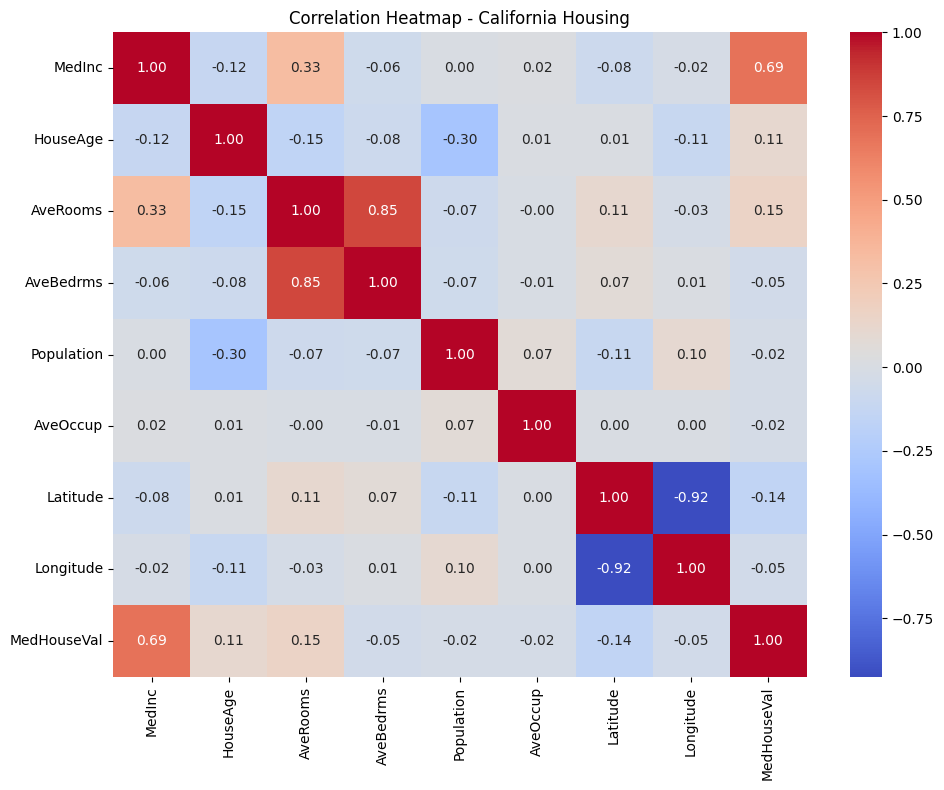

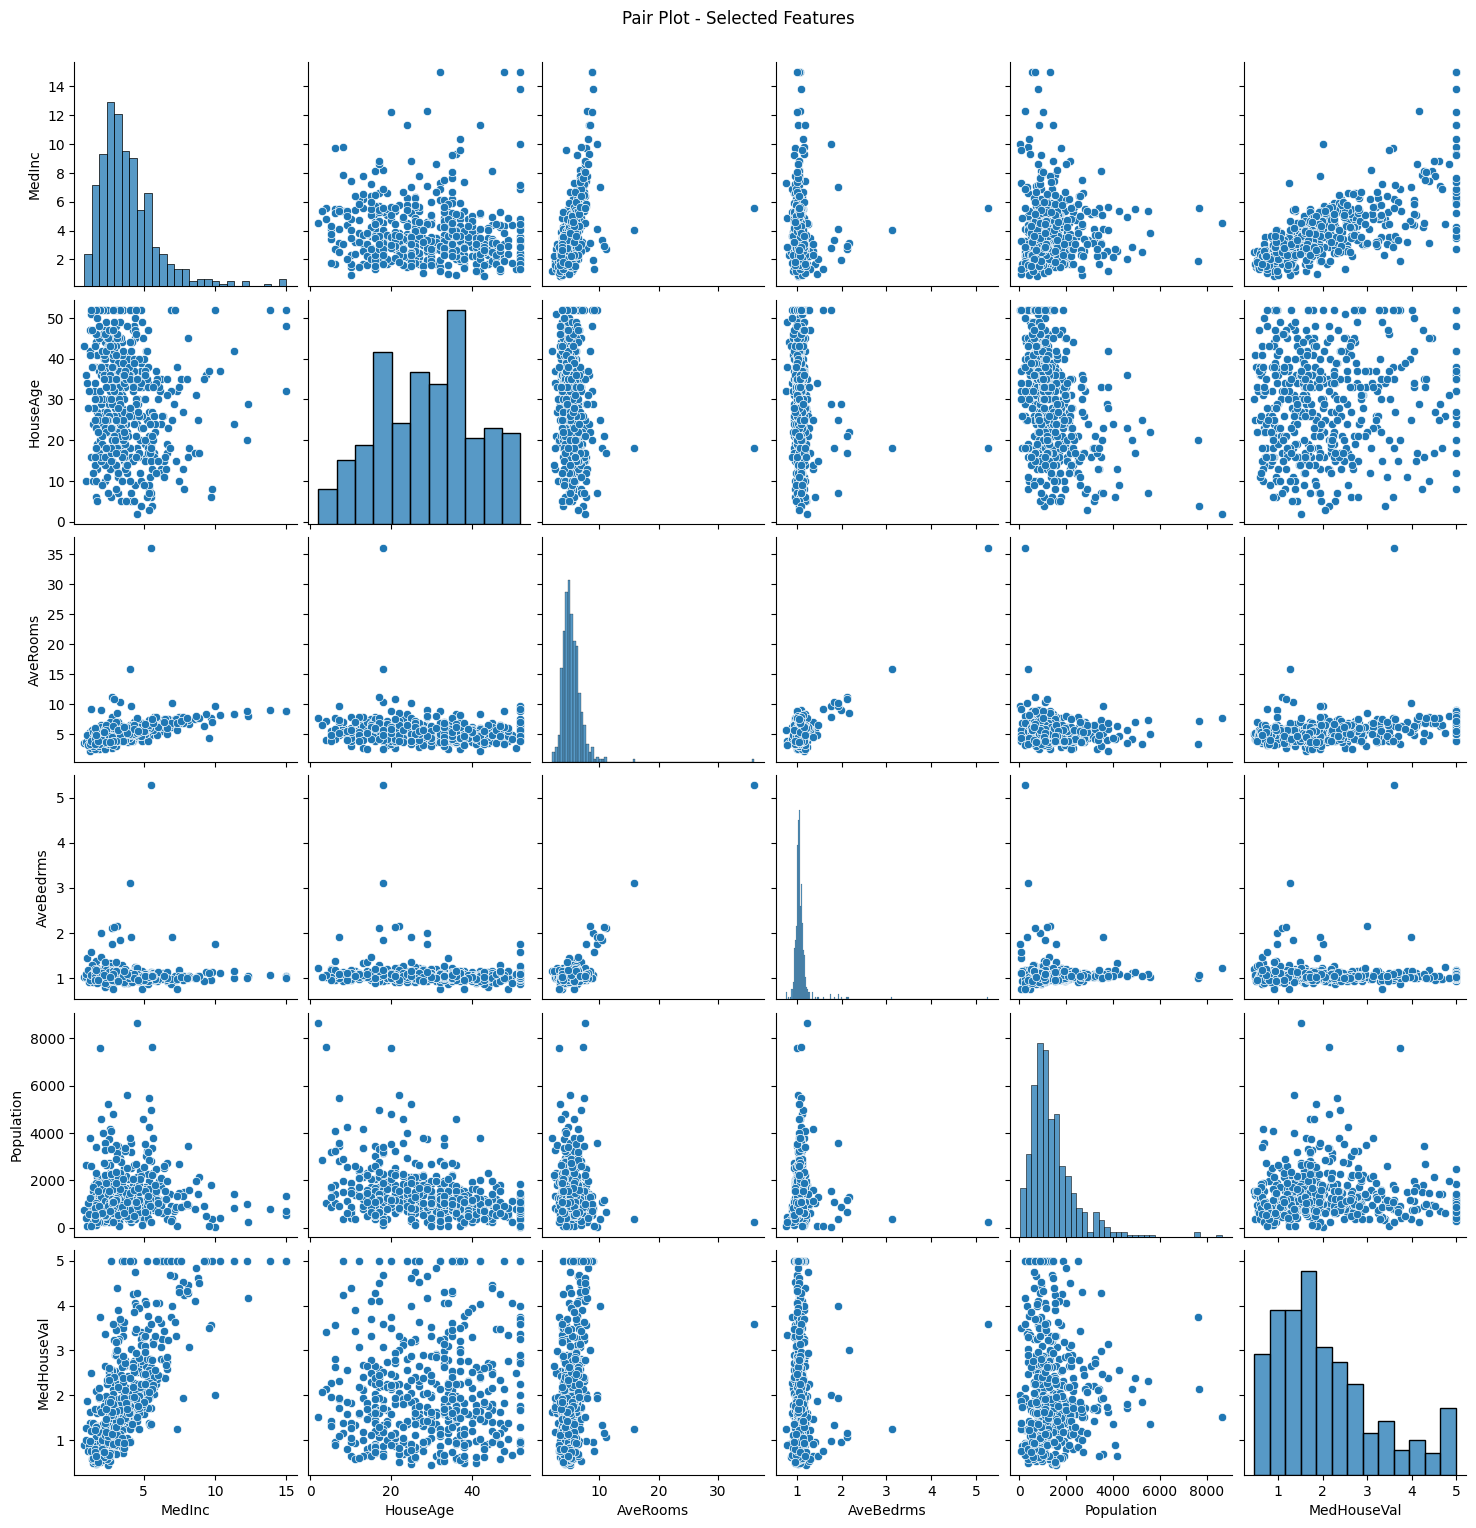

In [11]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap - California Housing")
plt.tight_layout()
plt.show()
features = ["MedInc", "HouseAge", "AveRooms", "AveBedrms", "Population", "MedHouseVal"]
sns.pairplot(df[features].sample(500, random_state=42), diag_kind="hist")
plt.suptitle("Pair Plot - Selected Features", y=1.02)
plt.show()

# Assignment 5:- Write a program to implement the naïve Bayesian classifier for a sample training data set. Compute the accuracy of the classifier, considering few test data sets.

In [12]:
import math
from collections import defaultdict

In [13]:
data = [
 ["Sunny","Hot","High","False","No"], ["Sunny","Hot","High","True","No"],
 ["Overcast","Hot","High","False","Yes"], ["Rain","Mild","High","False","Yes"],
 ["Rain","Cool","Normal","False","Yes"], ["Rain","Cool","Normal","True","No"],
 ["Overcast","Cool","Normal","True","Yes"], ["Sunny","Mild","High","False","No"],
 ["Sunny","Cool","Normal","False","Yes"], ["Rain","Mild","Normal","False","Yes"],
 ["Sunny","Mild","Normal","True","Yes"], ["Overcast","Mild","High","True","Yes"],
 ["Overcast","Hot","Normal","False","Yes"], ["Rain","Mild","High","True","No"]]
train, test = data[:10], data[10:]


In [14]:
class NaiveBayes:
    def fit(self, rows):
        self.classes = defaultdict(int)
        self.counts = defaultdict(lambda: defaultdict(lambda: defaultdict(int)))
        self.values = defaultdict(set)
        self.total = len(rows)
        for row in rows:
            x, label = row[:-1], row[-1]
            self.classes[label] += 1
            for i, value in enumerate(x):
                self.counts[i][value][label] += 1
                self.values[i].add(value)
    def predict(self, x):
        scores = {}
        for label, count in self.classes.items():
            score = math.log(count / self.total)
            for i, value in enumerate(x):
                score += math.log((self.counts[i][value][label] + 1) / (count + len(self.values[i])))
            scores[label] = score
        return max(scores, key=scores.get)

model = NaiveBayes(); model.fit(train)
correct = 0
for row in test:
    pred = model.predict(row[:-1]); actual = row[-1]
    print("Features:", row[:-1], "Predicted:", pred, "Actual:", actual)
    correct += pred == actual
print("Accuracy:", correct / len(test))


Features: ['Sunny', 'Mild', 'Normal', 'True'] Predicted: No Actual: Yes
Features: ['Overcast', 'Mild', 'High', 'True'] Predicted: Yes Actual: Yes
Features: ['Overcast', 'Hot', 'Normal', 'False'] Predicted: Yes Actual: Yes
Features: ['Rain', 'Mild', 'High', 'True'] Predicted: No Actual: No
Accuracy: 0.75


## Assignment 6 :Write a program to implement k-Nearest Neighbor algorithm to classify the iris data set. Print both correct and wrong predictionsusing Python ML library classes.

In [15]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

In [16]:
iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(iris.data, iris.target, test_size=0.30, random_state=32, stratify=iris.target)
model = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, pred))
for i in range(len(y_test)):
    actual, guessed = iris.target_names[y_test[i]], iris.target_names[pred[i]]
    status = "Correct" if y_test[i] == pred[i] else "Wrong"
    print(status, "| Predicted:", guessed, "| Actual:", actual)


Accuracy: 0.9777777777777777
Correct | Predicted: versicolor | Actual: versicolor
Correct | Predicted: setosa | Actual: setosa
Correct | Predicted: setosa | Actual: setosa
Correct | Predicted: setosa | Actual: setosa
Correct | Predicted: setosa | Actual: setosa
Correct | Predicted: versicolor | Actual: versicolor
Correct | Predicted: versicolor | Actual: versicolor
Correct | Predicted: setosa | Actual: setosa
Correct | Predicted: virginica | Actual: virginica
Correct | Predicted: virginica | Actual: virginica
Correct | Predicted: versicolor | Actual: versicolor
Correct | Predicted: setosa | Actual: setosa
Correct | Predicted: versicolor | Actual: versicolor
Correct | Predicted: versicolor | Actual: versicolor
Correct | Predicted: virginica | Actual: virginica
Correct | Predicted: setosa | Actual: setosa
Wrong | Predicted: virginica | Actual: versicolor
Correct | Predicted: virginica | Actual: virginica
Correct | Predicted: versicolor | Actual: versicolor
Correct | Predicted: virginica 

# Assignment 7: 
- Write a program to demonstrate the working of the decision tree based ID3 algorithm using appropriate data set for building the decision tree and apply this knowledge to classify a new sample.

In [17]:
import math
from collections import Counter

data = [
 ["Sunny","Hot","High","False","No"], ["Sunny","Hot","High","True","No"],
 ["Overcast","Hot","High","False","Yes"], ["Rain","Mild","High","False","Yes"],
 ["Rain","Cool","Normal","False","Yes"], ["Rain","Cool","Normal","True","No"],
 ["Overcast","Cool","Normal","True","Yes"], ["Sunny","Mild","High","False","No"],
 ["Sunny","Cool","Normal","False","Yes"], ["Rain","Mild","Normal","False","Yes"],
 ["Sunny","Mild","Normal","True","Yes"], ["Overcast","Mild","High","True","Yes"],
 ["Overcast","Hot","Normal","False","Yes"], ["Rain","Mild","High","True","No"]]
features = ["Outlook", "Temperature", "Humidity", "Windy"]

def entropy(rows):
    counts = Counter(r[-1] for r in rows); total = len(rows)
    return -sum((n/total)*math.log2(n/total) for n in counts.values())
def gain(rows, idx):
    result = entropy(rows)
    for value in set(r[idx] for r in rows):
        subset = [r for r in rows if r[idx] == value]
        result -= len(subset)/len(rows)*entropy(subset)
    return result
def id3(rows, names):
    labels = [r[-1] for r in rows]
    if len(set(labels)) == 1: return labels[0]
    if not names: return Counter(labels).most_common(1)[0][0]
    gains = [gain(rows, i) for i in range(len(names))]
    best = gains.index(max(gains)); feature = names[best]
    tree = {feature: {}}
    for value in set(r[best] for r in rows):
        subset = [r[:best] + r[best+1:] for r in rows if r[best] == value]
        tree[feature][value] = id3(subset, names[:best] + names[best+1:])
    return tree
def predict(tree, sample, all_names):
    if isinstance(tree, str): return tree
    feature = next(iter(tree)); value = sample[all_names.index(feature)]
    if value not in tree[feature]: return "Unknown"
    return predict(tree[feature][value], sample, all_names)

tree = id3(data, features)
print("Decision Tree (ID3):", tree)
sample = ["Sunny", "Cool", "High", "True"]
print("New sample:", sample)
print("Predicted class:", predict(tree, sample, features))


Decision Tree (ID3): {'Outlook': {'Rain': {'Windy': {'True': 'No', 'False': 'Yes'}}, 'Sunny': {'Humidity': {'Normal': 'Yes', 'High': 'No'}}, 'Overcast': 'Yes'}}
New sample: ['Sunny', 'Cool', 'High', 'True']
Predicted class: No


# Assignment 8: 
- Design and Develop a Program for Random Forest Classification

In [18]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

wine = load_wine()
X_train, X_test, y_train, y_test = train_test_split(wine.data, wine.target, test_size=0.30, random_state=42, stratify=wine.target)
model = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)
pred = model.predict(X_test)
print("Random Forest Classification")
print("Accuracy:", accuracy_score(y_test, pred))
print("Classification Report:\n", classification_report(y_test, pred, target_names=wine.target_names))
new_wine = [[14.23, 1.71, 2.43, 15.6, 127, 2.8, 3.06, 0.28, 2.29, 5.64, 1.04, 3.92, 1065]]
print("Predicted wine class:", wine.target_names[model.predict(new_wine)[0]])


Random Forest Classification
Accuracy: 1.0
Classification Report:
               precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        18
     class_1       1.00      1.00      1.00        21
     class_2       1.00      1.00      1.00        15

    accuracy                           1.00        54
   macro avg       1.00      1.00      1.00        54
weighted avg       1.00      1.00      1.00        54

Predicted wine class: class_0


# Assignment 9:Write a program to implement K -means clustering algorithm.
- Select your own dataset to test the program.
- Demonstrate the nature of output with varying value of K.

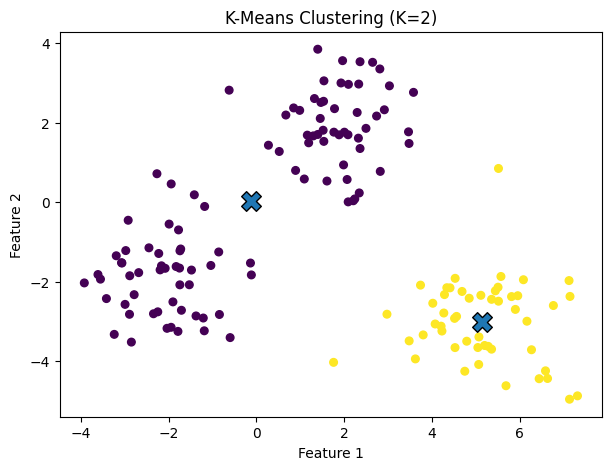

K=2, Inertia (WCSS)=1036.89


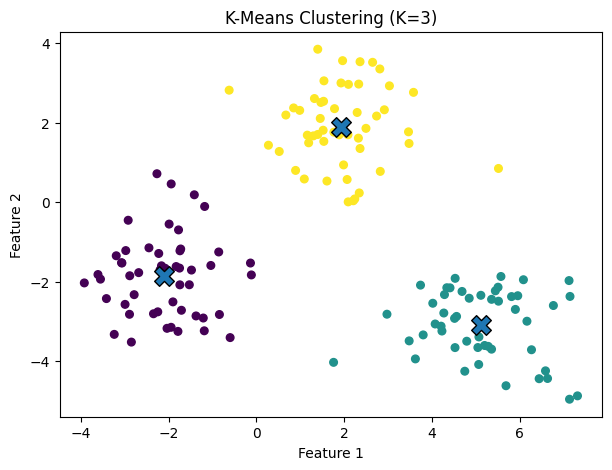

K=3, Inertia (WCSS)=285.09


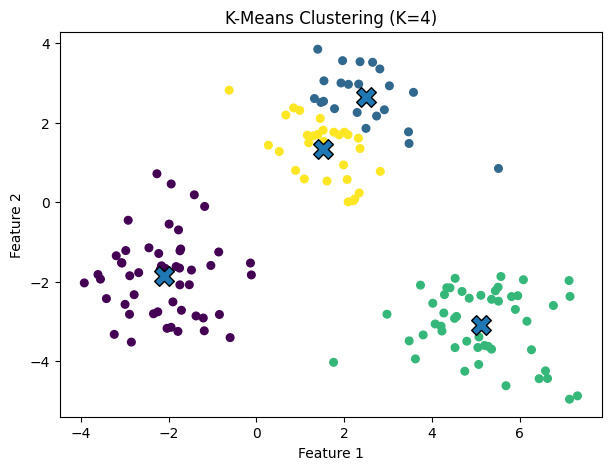

K=4, Inertia (WCSS)=252.02


In [20]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

np.random.seed(42)
X = np.vstack([np.random.randn(50, 2) + [2, 2], np.random.randn(50, 2) + [-2, -2], np.random.randn(50, 2) + [5, -3]])
for k in [2, 3, 4]:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X)
    plt.figure(figsize=(7, 5))
    plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", s=30)
    plt.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1], marker="X", s=200, edgecolors="black")
    plt.title(f"K-Means Clustering (K={k})")
    plt.xlabel("Feature 1"); plt.ylabel("Feature 2")
    plt.show()
    print(f"K={k}, Inertia (WCSS)={model.inertia_:.2f}")


# Assignment 10 :
- Build an Artificial Neural Network by implementing the Backpropagation algorithm and test the same using appropriate data sets

In [22]:
import numpy as np
np.random.seed(1)

def sigmoid(x): return 1 / (1 + np.exp(-x))
def sigmoid_derivative(out): return out * (1 - out)

X = np.array([[0,0], [0,1], [1,0], [1,1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)
w1 = np.random.rand(2, 4)
w2 = np.random.rand(4, 1)
learning_rate = 1.0

for epoch in range(10000):
    hidden = sigmoid(X @ w1)
    output = sigmoid(hidden @ w2)
    output_delta = (y - output) * sigmoid_derivative(output)
    hidden_delta = (output_delta @ w2.T) * sigmoid_derivative(hidden)
    w2 += learning_rate * hidden.T @ output_delta
    w1 += learning_rate * X.T @ hidden_delta

print("Final outputs after training:")
print(output.round(3))

print()
print("Predicted classes:")
print((output >= 0.5).astype(int))


Final outputs after training:
[[0.017]
 [0.983]
 [0.984]
 [0.016]]

Predicted classes:
[[0]
 [1]
 [1]
 [0]]


- Raw mterial

MACHINE LEARNING LAB MANUAL - ASSIGNMENTS 1 TO 10

Install packages:
python -m pip install numpy pandas scipy matplotlib seaborn scikit-learn

DATASET LINKS
1. Heart dataset (Assignment 1): https://www.kaggle.com/datasets/zhaoyingzhu/heartcsv
   Download the CSV, rename it Heart.csv, and place it beside Assignment_1.py.
4. California Housing (Assignment 4): built into scikit-learn; first run may download data.
   https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_california_housing.html
6. Iris (Assignment 6): built into scikit-learn, no separate download.
   https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html
8. Wine (Assignment 8): built into scikit-learn, no separate download.
   https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html
Assignments 5 and 7 include a weather dataset in the code. Assignment 9 generates sample data. Assignment 10 uses the XOR dataset.

Run separately, for example: python Assignment_1.py
Assignment 1 requires Heart.csv in the same folder.
